In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# ============================================================
# 0. 读入与基础清洗
# ============================================================
df = pd.read_csv(r'D:/UserBehavior.csv',
    names=['user_id', 'product_id', 'product_cat_id', 'behavior', 'behavior_time'],
    dtype={'user_id': 'int32', 'product_id': 'int32',
           'product_cat_id': 'int32', 'behavior': 'category',
           'behavior_time': 'int64'}
)

# 时间戳转 datetime（UTC+8）
df['dt'] = pd.to_datetime(df['behavior_time'], unit='s', utc=True) \
             .dt.tz_convert('Asia/Shanghai').dt.tz_localize(None)

t_min, t_max = df['dt'].min(), df['dt'].max()
print(f'观测区间：{t_min} ~ {t_max}，跨度 {(t_max - t_min).total_seconds()/86400:.1f} 天')

# 去重（天池该数据集存在完全重复记录）
n0 = len(df)
df = df.drop_duplicates()
print(f'去重：{n0} -> {len(df)}，删除 {n0 - len(df)} 条')

# 合理性校验：时间越界、空值
assert df[['user_id', 'product_id', 'product_cat_id', 'behavior']].notna().all().all()

观测区间：1902-05-08 06:32:46 ~ 2037-04-09 13:22:35，跨度 49280.3 天
去重：100150807 -> 100150758，删除 49 条


In [2]:
# ============================================================
# 1. 构建「加购-购买」匹配表（核心口径）
# ============================================================
KEYS = ['user_id', 'product_id', 'product_cat_id']

cart = (df[df['behavior'] == 'cart']
        .groupby(KEYS)['dt'].min()
        .rename('cart_time').reset_index())

buy = (df[df['behavior'] == 'buy']
       .groupby(KEYS)['dt'].min()
       .rename('buy_time').reset_index())

combo = cart.merge(buy, on=KEYS, how='left')

# 时间顺序合规：仅保留 buy_time >= cart_time；先买后加购的置为 NaN（视为无有效购买）
bad_order = combo['buy_time'].notna() & (combo['buy_time'] < combo['cart_time'])
print(f'时序倒置（先买后加购）记录：{bad_order.sum()} 条，已置空')
combo.loc[bad_order, 'buy_time'] = pd.NaT

combo['gap_h'] = (combo['buy_time'] - combo['cart_time']).dt.total_seconds() / 3600

print(f'去重「用户-商品」加购对总数：{len(combo):,}')
print(f'其中有过购买：{combo["buy_time"].notna().sum():,}')

时序倒置（先买后加购）记录：20671 条，已置空
去重「用户-商品」加购对总数：5,386,609
其中有过购买：326,468


In [3]:
# ============================================================
# 2. 右删失处理：剔除观测期末 48h 内才加购的样本
# ============================================================
CENSOR_CUT = t_max - pd.Timedelta(hours=48)

n_before = len(combo)
combo_c = combo[combo['cart_time'] <= CENSOR_CUT].copy()
print(f'右删失剔除：{n_before:,} -> {len(combo_c):,}'
      f'（剔除 {n_before - len(combo_c):,} 条，占 {(n_before - len(combo_c))/n_before:.2%}）')

# ============================================================
# 3. 四分类标签（互斥且完备）
# ============================================================
conditions = [
    combo_c['buy_time'].isna(),
    combo_c['gap_h'] <= 48,
    combo_c['gap_h'] > 48,
]
labels = ['未购买(流失)', '48h内购买', '48h外购买']
combo_c['seg'] = np.select(conditions, labels, default='未知')

seg_cnt = combo_c['seg'].value_counts()
seg_rate = (seg_cnt / seg_cnt.sum()).rename('rate')
summary = pd.concat([seg_cnt.rename('cnt'), (seg_rate * 100).round(2).rename('pct_%')], axis=1)
print('\n=== 四种状态分布（右删失修正后） ===')
print(summary)
print(f'校验：各段占比合计 = {seg_rate.sum():.4f}')

# 附：不做删失修正的对照，用于量化偏倚
seg_raw = np.select(
    [combo['buy_time'].isna(), combo['gap_h'] <= 48, combo['gap_h'] > 48],
    labels, default='未知')
raw_rate = pd.Series(seg_raw).value_counts(normalize=True) * 100
print('\n=== 未修正删失的口径（用于对比偏倚） ===')
print(raw_rate.round(2))

右删失剔除：5,386,609 -> 5,386,609（剔除 0 条，占 0.00%）

=== 四种状态分布（右删失修正后） ===
             cnt  pct_%
seg                    
未购买(流失)  5060141  93.94
48h内购买    259663   4.82
48h外购买     66805   1.24
校验：各段占比合计 = 1.0000

=== 未修正删失的口径（用于对比偏倚） ===
未购买(流失)    93.94
48h内购买      4.82
48h外购买      1.24
Name: proportion, dtype: float64


In [4]:
# ============================================================
# 4. 复购率（单独定义，不与流失率混）
#    定义：同一 user 对同一 product 出现 >=2 次 buy
# ============================================================
buy_cnt_per_pair = (df[df['behavior'] == 'buy']
                    .groupby(KEYS).size().rename('n_buy').reset_index())
combo_c = combo_c.merge(buy_cnt_per_pair, on=KEYS, how='left')
combo_c['n_buy'] = combo_c['n_buy'].fillna(0).astype(int)

repurchase_rate = (combo_c['n_buy'] >= 2).mean()
print(f'\n同品复购率（同用户同商品购买≥2次）：{repurchase_rate:.2%}')


同品复购率（同用户同商品购买≥2次）：0.35%


In [5]:
# ============================================================
# 5. 品类层面：带最小样本阈值 + Wilson 置信区间
# ============================================================
def wilson_ci(k, n, z=1.96):
    """k=成功数, n=样本数；返回 (lower, upper)"""
    if n == 0:
        return np.nan, np.nan
    p = k / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return center - half, center + half

cat = (combo_c.groupby('product_cat_id')
       .agg(cart_cnt=('user_id', 'size'),
            lost_cnt=('seg', lambda s: (s == '未购买(流失)').sum()),
            fast_buy=('seg', lambda s: (s == '48h内购买').sum()),
            slow_buy=('seg', lambda s: (s == '48h外购买').sum()))
       .reset_index())

cat['loss_rate'] = cat['lost_cnt'] / cat['cart_cnt']
cat['fast_rate'] = cat['fast_buy'] / cat['cart_cnt']
cat['slow_rate'] = cat['slow_buy'] / cat['cart_cnt']

# 销量 / 购买人次（用去重加购对口径，与分母一致）
buy_agg = (combo_c[combo_c['buy_time'].notna()]
           .groupby('product_cat_id')
           .size().rename('buy_pair_cnt').reset_index())
cat = cat.merge(buy_agg, on='product_cat_id', how='left')
cat['buy_pair_cnt'] = cat['buy_pair_cnt'].fillna(0).astype(int)

ci = cat.apply(lambda r: wilson_ci(r['lost_cnt'], r['cart_cnt']), axis=1, result_type='expand')
cat[['ci_low', 'ci_high']] = ci

MIN_CART = 500           # 最小样本阈值，可按需调整
cat_v = cat[cat['cart_cnt'] >= MIN_CART].copy()
print(f'\n品类总数 {len(cat)}，加购量≥{MIN_CART} 的品类 {len(cat_v)} 个，'
      f'覆盖加购对 {cat_v["cart_cnt"].sum():,} / {cat["cart_cnt"].sum():,}'
      f'（{cat_v["cart_cnt"].sum()/cat["cart_cnt"].sum():.1%}）')

print('\n=== 流失率最高 TOP10（加购量≥%d，按 Wilson 下界排序更稳健）===' % MIN_CART)
print(cat_v.sort_values('ci_low', ascending=False)
      .head(10)[['product_cat_id', 'cart_cnt', 'lost_cnt', 'loss_rate', 'ci_low', 'ci_high']]
      .round(4).to_string(index=False))

print('\n=== 流失率最低 TOP10 ===')
print(cat_v.sort_values('ci_high', ascending=True)
      .head(10)[['product_cat_id', 'cart_cnt', 'lost_cnt', 'loss_rate', 'ci_low', 'ci_high']]
      .round(4).to_string(index=False))


品类总数 7532，加购量≥500 的品类 1098 个，覆盖加购对 4,919,941 / 5,386,609（91.3%）

=== 流失率最高 TOP10（加购量≥500，按 Wilson 下界排序更稳健）===
 product_cat_id  cart_cnt  lost_cnt  loss_rate  ci_low  ci_high
        4655941      1261      1250     0.9913  0.9844   0.9951
        4466876      1215      1203     0.9901  0.9828   0.9943
        1165503      1319      1304     0.9886  0.9813   0.9931
        2352202      1546      1523     0.9851  0.9778   0.9901
         154040     28341     27743     0.9789  0.9772   0.9805
        4589142      2618      2570     0.9817  0.9758   0.9861
        2181935      5810      5691     0.9795  0.9755   0.9829
        2892802      5677      5559     0.9792  0.9752   0.9826
        1438507       913       899     0.9847  0.9744   0.9908
        4476428      3942      3857     0.9784  0.9734   0.9825

=== 流失率最低 TOP10 ===
 product_cat_id  cart_cnt  lost_cnt  loss_rate  ci_low  ci_high
         750949      1425      1208     0.8477  0.8281   0.8654
        1023823       952       804 

In [6]:
# ============================================================
# 6. 权重贡献：谁在"贡献"总体流失率（而非谁率最高）
# ============================================================
total_lost = cat['lost_cnt'].sum()
cat['lost_share'] = cat['lost_cnt'] / total_lost                       # 流失量贡献占比
cat['excess_lost'] = cat['lost_cnt'] - cat['cart_cnt'] * (total_lost / cat['cart_cnt'].sum())
# excess_lost > 0 表示该品类流失量超出"同规模平均水平"

print('\n=== 流失量绝对贡献 TOP10（谁把总体流失率抬上去的）===')
print(cat.sort_values('lost_cnt', ascending=False)
      .head(10)[['product_cat_id', 'cart_cnt', 'lost_cnt', 'loss_rate',
                 'lost_share', 'excess_lost']]
      .round(4).to_string(index=False))


=== 流失量绝对贡献 TOP10（谁把总体流失率抬上去的）===
 product_cat_id  cart_cnt  lost_cnt  loss_rate  lost_share  excess_lost
        4756105    210157    202382     0.9630      0.0400    4962.0551
        4145813    170764    163019     0.9546      0.0322    2604.5504
         982926    150491    144503     0.9602      0.0286    3132.8580
        2355072    118965    115687     0.9724      0.0229    3932.1513
        4801426    119235    113043     0.9481      0.0223    1034.5152
        3607361    105956    102512     0.9675      0.0203    2977.7105
        1320293     92568     88639     0.9576      0.0175    1681.2995
        2735466     91230     84914     0.9308      0.0168    -786.7931
        2520377     84768     82430     0.9724      0.0163    2799.5623
        2465336     82635     79369     0.9605      0.0157    1742.2869


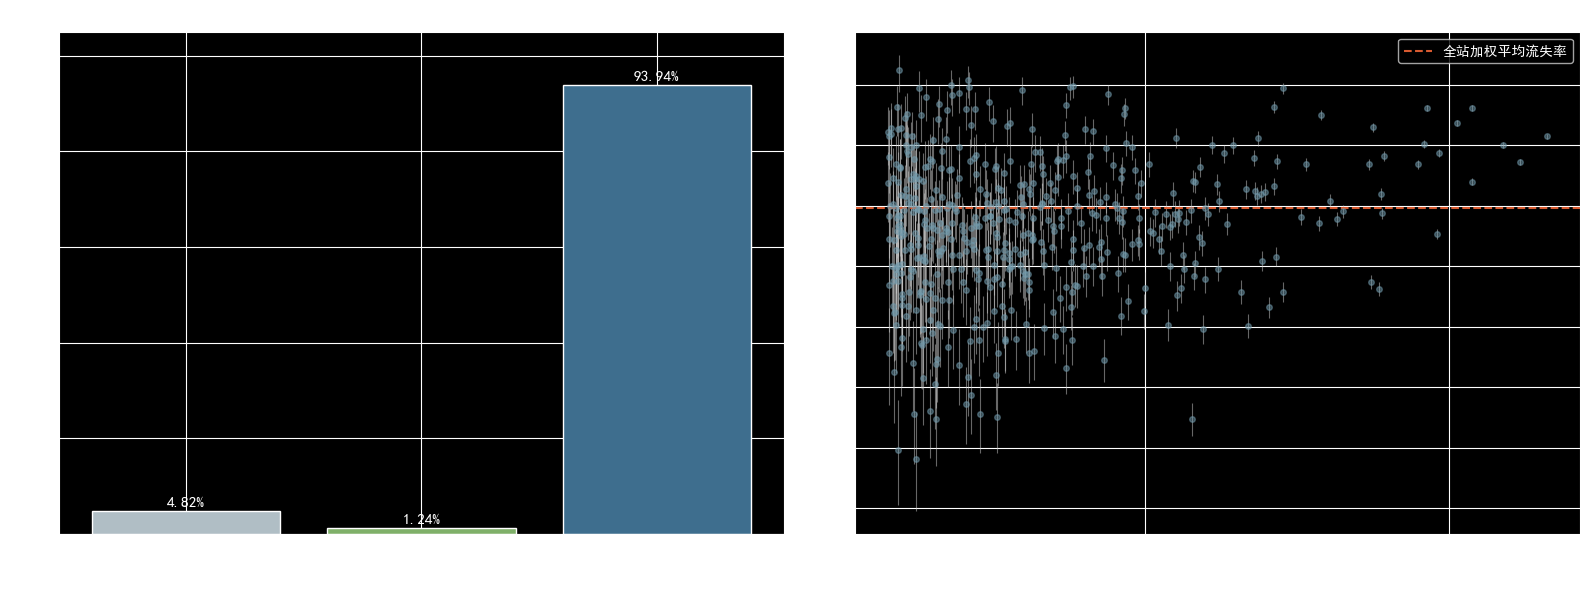

In [7]:
# ============================================================
# 7. 可视化
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6), facecolor='white')

# (a) 状态结构占比
ax = axes[0]
colors = ['#B0BEC5', '#7FB069', '#3E6E8E']
order = ['48h内购买', '48h外购买', '未购买(流失)']
vals = [seg_rate.get(k, 0) * 100 for k in order]
bars = ax.bar(order, vals, color=colors)
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width()/2, v + 1, f'{v:.2f}%', ha='center', fontsize=11)
ax.set_xlabel('加购后状态')
ax.set_ylabel('占去重加购对比例（%）')
ax.set_title('购物车加购后的状态分布（右删失修正后）')
ax.set_ylim(0, 105)

# (b) 品类：加购量 vs 流失率（带 CI 误差棒）
ax = axes[1]
sub = cat_v.nlargest(500, 'cart_cnt')
ax.errorbar(sub['cart_cnt'], sub['loss_rate'],
            yerr=[sub['loss_rate'] - sub['ci_low'], sub['ci_high'] - sub['loss_rate']],
            fmt='o', ms=4, alpha=0.5, color='#719AAC',
            ecolor='#CCCCCC', elinewidth=0.8, capsize=0)
ax.axhline(total_lost / cat['cart_cnt'].sum(), color='#D85A30',
           ls='--', lw=1.5, label='全站加权平均流失率')
ax.set_xscale('log')
ax.set_xlabel('品类加购对数量（对数刻度）')
ax.set_ylabel('品类流失率')
ax.set_title('品类加购规模 × 流失率（含 95% Wilson 置信区间）')
ax.legend()

plt.tight_layout()
plt.show()

In [8]:
# ============================================================
# 8. 稳健性检查：48h 阈值敏感性
# ============================================================
print('\n=== 阈值敏感性分析（流失率随窗口变化）===')
for h in [24, 48, 72, 168]:
    lost = (combo_c['buy_time'].isna() | (combo_c['gap_h'] > h)).mean()
    print(f'  窗口 {h:>3}h：流失率 = {lost:.2%}')


=== 阈值敏感性分析（流失率随窗口变化）===
  窗口  24h：流失率 = 96.40%
  窗口  48h：流失率 = 95.18%
  窗口  72h：流失率 = 94.65%
  窗口 168h：流失率 = 93.99%
